In [6]:
import math

A0 = 1.5
B0 = 1.0
C0 = 0.0

raw_kc = input("Enter a positive value for Kc: ")
print("Type of raw input:", type(raw_kc))

try:
    Kc = float(raw_kc)
except ValueError:
    print("Error: Kc must be entered as a number.")
else:
    print("Type of converted Kc:", type(Kc))
    print("Converted Kc:", Kc)

    if not math.isfinite(Kc):
        print("Error: Kc must be a finite number.")
    elif Kc <= 0:
        print("Error: Kc must be greater than zero.")
    else:
        # Kc(1.5 - x)(1 - x) = x
        a = Kc
        b = -(2.5 * Kc + 1)
        c = 1.5 * Kc
        discriminant = b**2 - 4 * a * c

        print("\nQuadratic coefficients:")
        print(f"a = {a}")
        print(f"b = {b}")
        print(f"c = {c}")
        print(f"Discriminant = {discriminant}")

        if discriminant < 0:
            print("Error: The equation has no real roots.")
        else:
            root1 = (-b + math.sqrt(discriminant)) / (2 * a)
            root2 = (-b - math.sqrt(discriminant)) / (2 * a)
            print(f"Root 1 = {root1}")
            print(f"Root 2 = {root2}")

            valid_roots = [root for root in (root1, root2) if 0 <= root <= B0]
            if not valid_roots:
                print("Error: No physically meaningful root was found.")
            else:
                x = valid_roots[0]
                A_eq = A0 - x
                B_eq = B0 - x
                C_eq = x
                conversion = x / B0 * 100

                print("\nEquilibrium concentrations:")
                print(f"[A] = {A_eq:.4f} mol/L")
                print(f"[B] = {B_eq:.4f} mol/L")
                print(f"[C] = {C_eq:.4f} mol/L")
                print(f"Conversion of limiting reactant B = {conversion:.2f}%")

                if conversion >= 70:
                    print("Conversion classification: high")
                elif conversion >= 40:
                    print("Conversion classification: moderate")
                else:
                    print("Conversion classification: low")


Type of raw input: <class 'str'>
Type of converted Kc: <class 'float'>
Converted Kc: -2.0
Error: Kc must be greater than zero.


In [2]:
import math


# Part A: Euler simulation for a first-order reaction
c0 = 2.5
k = 0.04
dt = 1.0
total_time = 12

concentration = c0
print("Part A: Euler simulation")
print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")

for time in range(total_time + 1):
    conversion = (c0 - concentration) / c0 * 100
    print(f"{time:10d} {concentration:24.4f} {conversion:18.2f}")
    if time < total_time:
        concentration = concentration - k * concentration * dt

euler_concentration = concentration
exact_concentration = c0 * math.exp(-k * total_time)
absolute_error = abs(euler_concentration - exact_concentration)
print(f"\nEuler concentration at {total_time} min: {euler_concentration:.4f} mol/L")
print(f"Exact concentration at {total_time} min: {exact_concentration:.4f} mol/L")
print(f"Absolute error: {absolute_error:.6f} mol/L")

# Continue with Euler steps until conversion reaches 40% or time reaches 100 min.
concentration = c0
time = 0
conversion = 0.0

while conversion < 40.0 and time < 100:
    concentration = concentration - k * concentration * dt
    time += 1
    conversion = (c0 - concentration) / c0 * 100

print("\nPart A: 40% conversion stopping condition")
print(f"Time needed: {time} min")
print(f"Final concentration: {concentration:.4f} mol/L")


# Part B: Count and sum the digits in a sample code.
code = input("\nPart B: Enter a sample code: ")

if code == "":
    print("The code is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in code:
        if character.isdigit():
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("The code contains no digits.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")


Part A: Euler simulation
Time (min)    Concentration (mol/L)     Conversion (%)
         0                   2.5000               0.00
         1                   2.4000               4.00
         2                   2.3040               7.84
         3                   2.2118              11.53
         4                   2.1234              15.07
         5                   2.0384              18.46
         6                   1.9569              21.72
         7                   1.8786              24.86
         8                   1.8035              27.86
         9                   1.7313              30.75
        10                   1.6621              33.52
        11                   1.5956              36.18
        12                   1.5318              38.73

Euler concentration at 12 min: 1.5318 mol/L
Exact concentration at 12 min: 1.5470 mol/L
Absolute error: 0.015184 mol/L

Part A: 40% conversion stopping condition
Time needed: 13 min
Final concentration: 1

In [3]:
def factorial(n):
    if n < 0:
        raise ValueError("Factorial is not defined for negative integers.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0 or r > n:
        raise ValueError("Invalid input: require n >= 0 and 0 <= r <= n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


def fib_iter(n):
    if n < 0:
        raise ValueError("n must be non-negative.")

    numbers = []
    a, b = 0, 1
    for _ in range(n):
        numbers.append(a)
        a, b = b, a + b
    return numbers


def fib_rec(k):
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


print("Part A: Solvent combinations")
print(f"Possible mixtures for n=9, r=3: {combination(9, 3)}")

try:
    combination(6, 8)
except ValueError as error:
    print(f"n=6, r=8: {error}")

print("\nPart B: Crystallisation sampling schedule")
n = 10
tags = fib_iter(n)
recursive_tags = [fib_rec(k) for k in range(n)]

if tags != recursive_tags:
    raise RuntimeError("The Fibonacci functions do not agree.")

print("Iterative and recursive Fibonacci results agree.")
print(f"{'Sample No.':>10} {'Fibonacci tag':>14} {'Sampling time (min)':>20}")
for sample_no, tag in enumerate(tags, start=1):
    print(f"{sample_no:10d} {tag:14d} {tag * 4:20d}")

Part A: Solvent combinations
Possible mixtures for n=9, r=3: 84
n=6, r=8: Invalid input: require n >= 0 and 0 <= r <= n.

Part B: Crystallisation sampling schedule
Iterative and recursive Fibonacci results agree.
Sample No.  Fibonacci tag  Sampling time (min)
         1              0                    0
         2              1                    4
         3              1                    4
         4              2                    8
         5              3                   12
         6              5                   20
         7              8                   32
         8             13                   52
         9             21                   84
        10             34                  136


CSV shape: (6, 3)
CSV data types:
Time_min                      int64
Run1_mol_L_low_catalyst     float64
Run2_mol_L_high_catalyst    float64
dtype: object

Mean and sample standard deviation (mol/L):
      Run1_mol_L_low_catalyst  Run2_mol_L_high_catalyst
mean                 0.878333                  0.645000
std                  0.402414                  0.507494

Run 2 shows more variation by standard deviation.


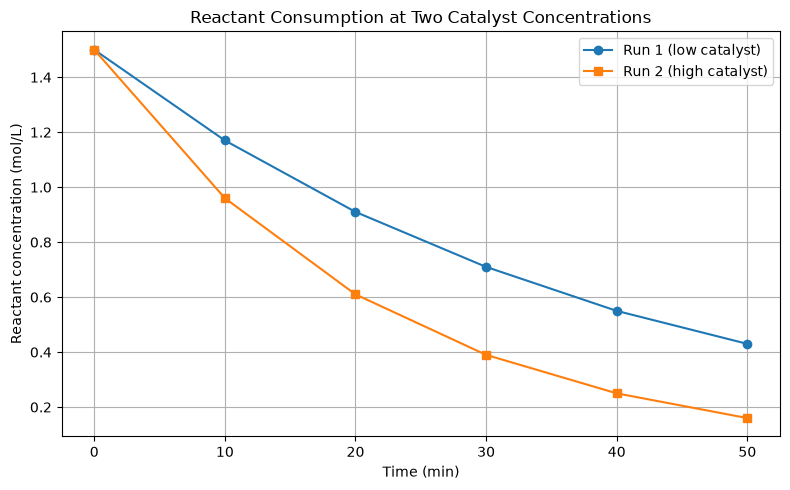


Mean P x V (k): 5.0220 bar L


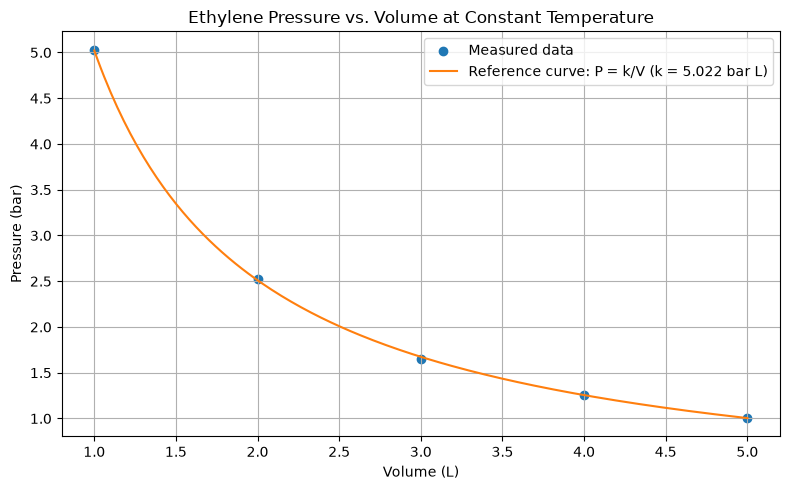

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reaction kinetics data
kinetics_df = pd.DataFrame({
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L_low_catalyst": [1.50, 1.17, 0.91, 0.71, 0.55, 0.43],
    "Run2_mol_L_high_catalyst": [1.50, 0.96, 0.61, 0.39, 0.25, 0.16],
})

kinetics_df.to_csv("kinetics.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=4)

kinetics_from_csv = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)

run_stats = kinetics_from_csv[
    ["Run1_mol_L_low_catalyst", "Run2_mol_L_high_catalyst"]
].agg(["mean", "std"])
print("\nMean and sample standard deviation (mol/L):")
print(run_stats)

if run_stats.loc["std", "Run1_mol_L_low_catalyst"] > run_stats.loc["std", "Run2_mol_L_high_catalyst"]:
    print("\nRun 1 shows more variation by standard deviation.")
else:
    print("\nRun 2 shows more variation by standard deviation.")

# Plot both concentration profiles.
plt.figure(figsize=(8, 5))
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run1_mol_L_low_catalyst"], marker="o", label="Run 1 (low catalyst)")
plt.plot(kinetics_from_csv["Time_min"], kinetics_from_csv["Run2_mol_L_high_catalyst"], marker="s", label="Run 2 (high catalyst)")
plt.title("Reactant Consumption at Two Catalyst Concentrations")
plt.xlabel("Time (min)")
plt.ylabel("Reactant concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Ethylene pressure-volume data and ideal-gas reference curve.
pv_df = pd.DataFrame({
    "Volume_L": [1, 2, 3, 4, 5],
    "Pressure_bar": [5.03, 2.52, 1.65, 1.26, 1.01],
})
k = (pv_df["Pressure_bar"] * pv_df["Volume_L"]).mean()
print(f"\nMean P x V (k): {k:.4f} bar L")

volume_curve = np.linspace(pv_df["Volume_L"].min(), pv_df["Volume_L"].max(), 200)
pressure_curve = k / volume_curve

plt.figure(figsize=(8, 5))
plt.scatter(pv_df["Volume_L"], pv_df["Pressure_bar"], label="Measured data", color="tab:blue")
plt.plot(volume_curve, pressure_curve, label=f"Reference curve: P = k/V (k = {k:.3f} bar L)", color="tab:orange")
plt.title("Ethylene Pressure vs. Volume at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()